# Coloration de graphes — validité statistique d'une comparaison de stratégies

**Navigation** : [Index de la partie](README.md) | [Version Python](App-02-GraphColoring-Statistical-Validity-Python.ipynb) | [App-2](App-02-GraphColoring-Python.ipynb)

**Objectifs** : comparer des colorations sur plusieurs graphes appariés ; calculer un intervalle bootstrap, un test de Wilcoxon et une taille d'effet ; examiner la densité. **Prérequis** : graphes, coloration gloutonne et CP-SAT. **Durée estimée** : 90 minutes.

Une seule instance ne suffit pas à établir une différence entre stratégies. Nous utilisons des graphes NetworkX, des algorithmes pédagogiques C#, CP-SAT natif .NET et les tests SciPy via Python.NET. Les graines rendent chaque implémentation reproductible dans son environnement ; elles ne rendent pas les générateurs Python et C# identiques.

In [1]:
// Le C# pilote les expériences ; les liaisons Python ciblent NetworkX et les vrais tests SciPy.
// Les optimisations de coloration utilisent le moteur OR-Tools natif.
#r "nuget: Google.OrTools, 9.15.6755"
#r "nuget: pythonnet, 3.1.0"
#load "../../Config/PythonNetLoader.cs"
using System;
using System.IO;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text.Json;
using System.Text;
using Google.OrTools.Sat;
using Python.Runtime;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "scipy");
Console.WriteLine($"Runtime {System.Runtime.InteropServices.RuntimeInformation.FrameworkDescription} ; OR-Tools {typeof(CpModel).Assembly.GetName().Version} ; Python {PythonEngine.Version}");


The below script needs to be able to find the current output cell; this is an easy method to get it.

Installed Packages Google.OrTools, 9.15.6755 pythonnet, 3.1.0

Runtime .NET 10.0.15 ; OR-Tools 9.15.6755.0 ; Python 3.13.16 | packaged by conda-forge | (main, Oct 13 2026, 16:50:31) [MSC v.1944 64 bit (AMD64)]


## 1. Mise en place — trois stratégies et les moteurs de référence

NetworkX tire $G(n,p)$. Le glouton suit l'ordre des sommets ; DSATUR choisit la saturation puis le degré. CP-SAT minimise les couleurs utilisées et distingue optimum prouvé, solution faisable et absence de solution. Son budget vaut **2 unités de temps déterministe**, avec un seul worker et une graine ; ce ne sont pas deux secondes murales.

In [2]:
// NetworkX génère les graphes tandis que les heuristiques et le modèle CP-SAT sont exécutés ici.
// Une résolution sans solution reste absente des métriques CP-SAT : aucun résultat glouton ne la remplace.
PyModule python;
using (Py.GIL())
{
    python = Py.CreateScope();
    python.Exec(@"import json, networkx as nx, scipy, scipy.stats as stats

def graph_json(n,p,seed):
    g=nx.gnp_random_graph(n,p,seed=seed)
    return json.dumps(list(g.edges()))

def tests_json(a,b):
    w=stats.wilcoxon(a,b,alternative='greater',zero_method='wilcox')
    u=stats.mannwhitneyu(a,b,alternative='greater')
    return json.dumps([float(w.statistic),float(w.pvalue),float(u.statistic),float(u.pvalue)])

def versions():
    return 'networkx '+nx.__version__+' ; scipy '+scipy.__version__");
    Console.WriteLine(python.Get("versions").Invoke().As<string>());
}

class Graphe
{
    public int N;
    public bool[, ] Adj;
    public Graphe(int n)
    {
        N = n;
        Adj = new bool[n, n];
    }

    // La matrice symétrique représente la même arête dans les deux sens.
    public void Arete(int u, int v)
    {
        Adj[u, v] = Adj[v, u] = true;
    }

    public int Degre(int v)
    {
        int d = 0;
        for (int w = 0; w < N; w++)
            if (Adj[v, w])
                d++;
        return d;
    }
}

Graphe Generer(int n, double p, int seed)
{
    string json;
    using (Py.GIL())
    {
        using var f = python.Get("graph_json");
        using var args = new PyTuple(new[] { n.ToPython(), p.ToPython(), seed.ToPython() });
        using var r = f.Invoke(args);
        json = r.As<string>();
    }

    var g = new Graphe(n);
    foreach (var edge in JsonSerializer.Deserialize<int[][]>(json))
        g.Arete(edge[0], edge[1]);
    return g;
}

(int, int[]) Glouton(Graphe g, int[] ordre = null)
{
    // Sans ordre imposé, le glouton suit les indices : ce choix influence sa qualité.
    ordre ??= Enumerable.Range(0, g.N).ToArray();
    var colors = Enumerable.Repeat(-1, g.N).ToArray();
    foreach (int v in ordre)
    {
        var used = new HashSet<int>();
        for (int w = 0; w < g.N; w++)
            if (g.Adj[v, w] && colors[w] >= 0)
                used.Add(colors[w]);
        int c = 0;
        while (used.Contains(c))
            c++;
        colors[v] = c;
    }

    return (colors.Length == 0 ? 0 : colors.Max() + 1, colors);
}

(int, int[]) Dsatur(Graphe g)
{
    var colors = Enumerable.Repeat(-1, g.N).ToArray();
    for (int i = 0; i < g.N; i++)
    {
        // DSATUR privilégie les couleurs voisines distinctes ; degré puis indice départagent.
        int v = Enumerable.Range(0, g.N).Where(v => colors[v] < 0).OrderByDescending(v => Enumerable.Range(0, g.N).Where(w => g.Adj[v, w] && colors[w] >= 0).Select(w => colors[w]).Distinct().Count()).ThenByDescending(v => g.Degre(v)).ThenBy(v => v).First();
        var used = Enumerable.Range(0, g.N).Where(w => g.Adj[v, w] && colors[w] >= 0).Select(w => colors[w]).ToHashSet();
        int c = 0;
        while (used.Contains(c))
            c++;
        colors[v] = c;
    }

    return (colors.Length == 0 ? 0 : colors.Max() + 1, colors);
}

bool Valide(Graphe g, int[] c)
{
    if (c.Length != g.N || c.Any(x => x < 0))
        return false;
    for (int i = 0; i < g.N; i++)
        for (int j = i + 1; j < g.N; j++)
            if (g.Adj[i, j] && c[i] == c[j])
                return false;
    return true;
}

(int? , string) CpColor(Graphe g, double limite = 2.0)
{
    if (g.N == 0)
        return (0, "Optimal");
    // Une coloration gloutonne fournit une borne réalisable pour le nombre de variables couleur.
    int ub = Glouton(g).Item1;
    var m = new CpModel();
    // x[v,c] affecte la couleur c au sommet v ; used[c] compte sa présence dans la solution.
    var x = new BoolVar[g.N, ub];
    var used = new BoolVar[ub];
    for (int v = 0; v < g.N; v++)
        for (int c = 0; c < ub; c++)
            x[v, c] = m.NewBoolVar($"x_{v}_{c}");
    // Chaque sommet reçoit une seule couleur, tandis que chaque arête interdit une couleur commune.
    for (int v = 0; v < g.N; v++)
        m.AddExactlyOne(Enumerable.Range(0, ub).Select(c => x[v, c]));
    for (int u = 0; u < g.N; u++)
        for (int v = u + 1; v < g.N; v++)
            if (g.Adj[u, v])
                for (int c = 0; c < ub; c++)
                    m.Add(x[u, c] + x[v, c] <= 1);
    for (int c = 0; c < ub; c++)
    {
        used[c] = m.NewBoolVar($"used_{c}");
        // Lier used à toutes les affectations empêche de minimiser des indicateurs déconnectés.
        m.AddMaxEquality(used[c], Enumerable.Range(0, g.N).Select(v => x[v, c]));
    }

    m.Minimize(LinearExpr.Sum(used));
    // Le budget est un temps déterministe du solveur, pas une durée murale portable.
    var solver = new CpSolver
    {
        StringParameters = $"max_deterministic_time:{limite.ToString(CultureInfo.InvariantCulture)} num_search_workers:1 random_seed:42"};
    var status = solver.Solve(m);
    // UNKNOWN ne fournit pas de coloration exploitable : on garde l’absence de mesure.
    if (status != CpSolverStatus.Optimal && status != CpSolverStatus.Feasible)
        return (null, status.ToString());
    var colors = Enumerable.Range(0, g.N).Select(v => Enumerable.Range(0, ub).Single(c => solver.Value(x[v, c]) == 1)).ToArray();
    if (!Valide(g, colors))
        throw new Exception("Coloration CP-SAT invalide");
    return (colors.Distinct().Count(), status.ToString());
}

Console.WriteLine("NetworkX, glouton, DSATUR et CP-SAT prêts ; colorations vérifiées sur les arêtes.");


networkx 3.6.1 ; scipy 1.18.1


NetworkX, glouton, DSATUR et CP-SAT prêts ; colorations vérifiées sur les arêtes.


## 2. Le piège de l'instance unique

Une instance $G(50,0{,}4)$ illustre une comparaison ponctuelle. Un nombre obtenu avec le statut `Feasible` est une borne supérieure, pas une preuve de $\chi$.

In [3]:
// La première instance vérifie la validité des colorations obtenues avant l’étude statistique.
// Une coloration faisable borne le nombre chromatique sans le prouver optimal.
var unique = Generer(50, 0.4, 42);
var(g1, gc1) = Glouton(unique);
var(d1, dc1) = Dsatur(unique);
var(c1, st1) = CpColor(unique);
if (!Valide(unique, gc1) || !Valide(unique, dc1))
    throw new Exception("Coloration heuristique invalide");
Console.WriteLine($"G(50,0.4) : glouton {g1}, DSATUR {d1}, CP-SAT {(c1.HasValue ? c1.ToString() : "sans solution")} ({st1})");


G(50,0.4) : glouton 12, DSATUR 9, CP-SAT 8 (Feasible)


### Lecture du résultat

Les trois méthodes ont reçu le même graphe. L'écart observé ne dit pas à lui seul ce qui se produit sur d'autres graphes.

### Exercice 1 — Welsh–Powell

Coloriez les sommets par degré décroissant, puis comparez au glouton sur les mêmes graphes. La garde contrôle des graphes non triviaux. Dans cette exécution, le glouton utilise 12 couleurs, DSATUR 9 et CP-SAT 8, avec le statut Feasible.

In [4]:
int? WelshPowell(Graphe g)
{
    return null;
} // TODO : trier les sommets par degré décroissant puis appeler Glouton

var e1 = new Graphe(4);
e1.Arete(0, 1);
e1.Arete(0, 2);
e1.Arete(0, 3);
var e2 = new Graphe(4);
e2.Arete(0, 1);
e2.Arete(1, 2);
e2.Arete(2, 0);
e2.Arete(2, 3);
var w1 = WelshPowell(e1);
var w2 = WelshPowell(e2);
var e3 = Generer(8, 0.35, 1);
var w3 = WelshPowell(e3);
if ((w1.HasValue && w1 != 2) || (w2.HasValue && w2 != 3) || (w3.HasValue && w3 != 3))
    throw new Exception("Coloration Welsh–Powell incorrecte");
bool welshPret = w1.HasValue && w2.HasValue && w3.HasValue;
Console.WriteLine(welshPret ? "Exercice 1 : fixtures vérifiées ; comparaison après le test statistique." : "Exercice 1 à compléter : Welsh–Powell");


Exercice 1 à compléter : Welsh–Powell


## 3. Distribution cross-instance

Échantillonnons 20 graphes indépendants $G(50,0{,}4)$, puis conservons uniquement les résolutions CP-SAT qui ont trouvé une solution. Les comparaisons impliquant CP-SAT resteront appariées sur ce sous-ensemble ; les colorations gloutonnes de repli sont annoncées séparément. Si des graphes sont exclus, ce sous-ensemble peut subir un biais de sélection : la comparaison ne permet pas alors de conclure pour toute la population des graphes.

In [5]:
// Les vingt graphes partagent les mêmes instances entre stratégies pour conserver l’appariement.
// Le masque CP-SAT exclut explicitement les résolutions sans solution des statistiques correspondantes.
var rng = new Random(42);
int N = 20;
var graphs = Enumerable.Range(0, N).Select(_ => Generer(50, 0.4, rng.Next(1, 1000000000))).ToArray();
var greedy = graphs.Select(g => Glouton(g).Item1).ToArray();
var dsatur = graphs.Select(g => Dsatur(g).Item1).ToArray();
var cp = graphs.Select(g => CpColor(g)).ToArray();
var mask = Enumerable.Range(0, N).Where(i => cp[i].Item1.HasValue).ToArray();
if (mask.Length == 0)
    throw new Exception("Aucune solution CP-SAT pour les statistiques");
// Les indices conservés servent aussi aux contrastes appariés pour comparer les mêmes graphes.
var cpvals = mask.Select(i => cp[i].Item1.Value).ToArray();
double Median(int[] a)
{
    var b = a.OrderBy(v => v).ToArray();
    return (b[(b.Length - 1) / 2] + b[b.Length / 2]) / 2.0;
}

void Resume(string nom, int[] a)
{
    double avg = a.Average();
    Console.WriteLine($"{nom, -9} moyenne={avg:F2} médiane={Median(a):F1} écart-type={Math.Sqrt(a.Select(v => (v - avg) * (v - avg)).Average()):F2} min/max={a.Min()}/{a.Max()}");
}

Resume("Glouton", greedy);
Resume("DSATUR", dsatur);
Resume("CP-SAT", cpvals);
Console.WriteLine($"CP-SAT : {cp.Count(v => v.Item2 == "Optimal")} Optimal, {cp.Count(v => v.Item2 == "Feasible")} Feasible, {N - mask.Length} sans solution");
foreach (int i in Enumerable.Range(0, N).Except(mask))
    Console.WriteLine($"Graphe {i} : {cp[i].Item2}, borne gloutonne séparée {greedy[i]}");


Glouton   moyenne=10.90 médiane=11.0 écart-type=0.83 min/max=9/12


DSATUR    moyenne=9.35 médiane=9.0 écart-type=0.65 min/max=8/10


CP-SAT    moyenne=7.95 médiane=8.0 écart-type=0.22 min/max=7/8


CP-SAT : 1 Optimal, 19 Feasible, 0 sans solution


### Lecture du résultat

Les moyennes, médianes et extrêmes décrivent l'échantillon. Les colorations faisables CP-SAT ne sont pas toutes des nombres chromatiques prouvés. Une boîte à moustaches résume médiane, quartiles et extrêmes observés. Les moyennes observées sont 10,90, 9,35 et 7,95 couleurs ; CP-SAT prouve un optimum sur une instance et trouve 19 solutions faisables.

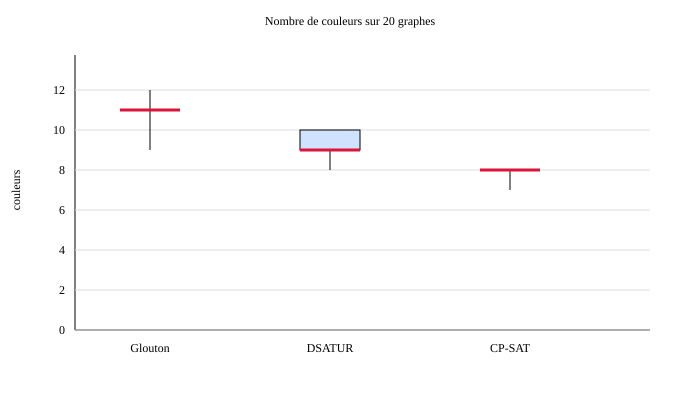

Boîtes : quartiles, médiane et extrêmes observés.


In [6]:
// Les boîtes utilisent les quantiles interpolés des couleurs obtenues sur les graphes mesurés.
// La séparation visuelle des distributions ne remplace pas le test apparié.
record Svg(string Content);
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Svg>((value, context) =>
{
    context.Writer.Write(value.Content);
    return true;
}, "image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(typeof(Svg), new[] { "image/svg+xml" });
double Quantile(double[] a, double q)
{
    var b = a.OrderBy(v => v).ToArray();
    // Interpoler entre statistiques d’ordre évite de réduire les quartiles à un arrondi d’indice.
    double z = (b.Length - 1) * q;
    int i = (int)z;
    return b[i] + (b[Math.Min(i + 1, b.Length - 1)] - b[i]) * (z - i);
}

var dataBox = new[]
{
    greedy,
    dsatur,
    cpvals
};
var nomsBox = new[]
{
    "Glouton",
    "DSATUR",
    "CP-SAT"
};
var svg = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='400' viewBox='0 0 700 400'><rect width='700' height='400' fill='white'/><text x='350' y='25' text-anchor='middle'>Nombre de couleurs sur 20 graphes</text><line x1='75' y1='330' x2='650' y2='330' stroke='black'/><line x1='75' y1='55' x2='75' y2='330' stroke='black'/><text x='20' y='190' transform='rotate(-90 20 190)' text-anchor='middle'>couleurs</text>");
int maxBox = dataBox.SelectMany(a => a).Max() + 1;
double Y(double y) => 330 - 260 * y / maxBox;
for (int t = 0; t <= maxBox; t += 2)
    svg.Append($"<line x1='75' y1='{Y(t):F2}' x2='650' y2='{Y(t):F2}' stroke='#ddd'/><text x='65' y='{Y(t) + 4:F2}' text-anchor='end'>{t}</text>");
for (int i = 0; i < 3; i++)
{
    var a = dataBox[i].Select(x => (double)x).ToArray();
    double q1 = Quantile(a, .25), q3 = Quantile(a, .75), med = Quantile(a, .5), x = 150 + i * 180;
    svg.Append($"<line x1='{x}' y1='{Y(a.Max()):F2}' x2='{x}' y2='{Y(a.Min()):F2}' stroke='black'/><rect x='{x - 30}' y='{Y(q3):F2}' width='60' height='{Y(q1) - Y(q3):F2}' fill='#cfe2ff' stroke='black'/><line x1='{x - 30}' y1='{Y(med):F2}' x2='{x + 30}' y2='{Y(med):F2}' stroke='crimson' stroke-width='3'/><text x='{x}' y='352' text-anchor='middle'>{nomsBox[i]}</text>");
}

svg.Append("</svg>");
display(new Svg(svg.ToString()));
Console.WriteLine("Boîtes : quartiles, médiane et extrêmes observés.");


## 4. Intervalle de confiance bootstrap à 95 %

Rééchantillonnons $B=2000$ fois avec remise, puis prenons les quantiles 2,5 % et 97,5 % des moyennes. Les intervalles décrivent chaque moyenne ; le test apparié de la section suivante porte directement sur les différences par graphe.

In [7]:
// Le bootstrap rééchantillonne les graphes avec remise pour estimer l’incertitude de la moyenne.
// Une graine fixe rend ce calcul reproductible dans ce générateur.
(double, double) Bootstrap(int[] a, int B = 2000, int seed = 42)
{
    var r = new Random(seed);
    var means = new double[B];
    for (int b = 0; b < B; b++)
    {
        double sum = 0;
        for (int i = 0; i < a.Length; i++)
            sum += a[r.Next(a.Length)];
        means[b] = sum / a.Length;
    }

    return (Quantile(means, .025), Quantile(means, .975));
}

foreach (var(nom, a)in new[]
{
    ("Glouton", greedy),
    ("DSATUR", dsatur),
    ("CP-SAT", cpvals)
}

)
{
    var(lo, hi) = Bootstrap(a);
    Console.WriteLine($"{nom, -9} moyenne={a.Average():F2} IC95%=[{lo:F2}, {hi:F2}] largeur={hi - lo:F2}");
}


Glouton   moyenne=10.90 IC95%=[10.50, 11.25] largeur=0.75


DSATUR    moyenne=9.35 IC95%=[9.05, 9.60] largeur=0.55


CP-SAT    moyenne=7.95 IC95%=[7.85, 8.00] largeur=0.15


### Lecture du résultat

Chaque intervalle est obtenu par rééchantillonnage des observations disponibles. L'amplitude reflète aussi la taille limitée de l'échantillon.

### Exercice 2 — Bootstrap de la médiane

Adaptez le bootstrap à la médiane. Pour rendre la garde reproductible, elle vérifie un cas constant, un jeu à deux valeurs et un échantillon de 100 valeurs avec un tirage fixé. Utilisez `System.Random(seed)` et le quantile linéaire défini ci-dessus pour rendre la garde reproductible. Les intervalles vont de [10,50 ; 11,25] pour le glouton à [7,85 ; 8,00] pour CP-SAT.

In [8]:
(double, double)? BootstrapMediane(int[] a, int B, int seed)
{
    return null;
} // TODO : rééchantillonner puis quantiles des médianes

(double, double) MedianeReference(int[] a, int B, int seed)
{
    var r = new Random(seed);
    var med = new double[B];
    for (int b = 0; b < B; b++)
    {
        var sample = Enumerable.Range(0, a.Length).Select(_ => a[r.Next(a.Length)]).OrderBy(x => x).ToArray();
        med[b] = (sample[(sample.Length - 1) / 2] + sample[sample.Length / 2]) / 2.0;
    }

    return (Quantile(med, .025), Quantile(med, .975));
}

bool VerifierMediane((double, double)? reponse, (double, double) attendu)
{
    if (!reponse.HasValue)
        return false;
    var(lo, hi) = reponse.Value;
    if (!double.IsFinite(lo) || !double.IsFinite(hi) || Math.Abs(lo - attendu.Item1) > 1e-9 || Math.Abs(hi - attendu.Item2) > 1e-9)
        throw new Exception("Bootstrap médiane incorrect");
    return true;
}

var bm1 = BootstrapMediane(new[] { 4, 4, 4, 4 }, 200, 42);
var bm2 = BootstrapMediane(new[] { 1, 1, 1, 9, 9 }, 2000, 42);
var bm3 = BootstrapMediane(Enumerable.Range(0, 100).ToArray(), 2000, 42);
bool okm1 = VerifierMediane(bm1, (4, 4));
bool okm2 = VerifierMediane(bm2, (1, 9));
bool okm3 = VerifierMediane(bm3, (39.5, 59));
if (!(okm1 && okm2 && okm3))
    Console.WriteLine("Exercice 2 à compléter : bootstrap médiane");
else
{
    var reel = BootstrapMediane(cpvals, 2000, 42);
    if (VerifierMediane(reel, MedianeReference(cpvals, 2000, 42)))
    {
        var moyenne = Bootstrap(cpvals);
        Console.WriteLine($"CP-SAT : moyenne {cpvals.Average():F2}, médiane {Median(cpvals):F2} ; IC médiane [{reel.Value.Item1:F2}, {reel.Value.Item2:F2}], largeur {reel.Value.Item2 - reel.Value.Item1:F2} ; largeur IC moyenne {moyenne.Item2 - moyenne.Item1:F2}");
    }
    else
        Console.WriteLine("Exercice 2 incomplet sur les données CP-SAT");
}


Exercice 2 à compléter : bootstrap médiane


## 5. Wilcoxon apparié et correction de Bonferroni

Chaque paire provient du même graphe. SciPy calcule le test unilatéral `greater`, avec `zero_method="wilcox"` qui exclut les différences nulles. Trois comparaisons imposent le seuil $0{,}05/3$. Le test indépendant de Mann–Whitney est aussi montré pour illustrer la différence de protocole. Sous l’hypothèse nulle, les différences appariées sont symétriques autour de zéro ; l’alternative unilatérale `greater` cherche un décalage positif, sous les hypothèses du test.

In [9]:
// Les tests SciPy comparent les mêmes observations appariées, après le masque CP-SAT si nécessaire.
// Les p-valeurs du protocole indépendant restent un contraste de méthode, pas une preuve plus forte.
double[] Tests(int[] a, int[] b)
{
    using (Py.GIL())
    {
        using var f = python.Get("tests_json");
        using var args = new PyTuple(new[] { a.ToPython(), b.ToPython() });
        using var r = f.Invoke(args);
        return JsonSerializer.Deserialize<double[]>(r.As<string>());
    }
}

var pairs = new[]
{
    ("Glouton > DSATUR", greedy, dsatur),
    ("DSATUR > CP-SAT", mask.Select(i => dsatur[i]).ToArray(), cpvals),
    ("Glouton > CP-SAT", mask.Select(i => greedy[i]).ToArray(), cpvals)
};
Console.WriteLine($"Seuil Bonferroni : {0.05 / 3:F4}");
foreach (var(nom, a, b)in pairs)
{
    var test = Tests(a, b);
    Console.WriteLine($"{nom, -20} W={test[0]:F1} p_W={test[1]:E3} significatif={test[1] < 0.05 / 3} ; p_MannWhitney={test[3]:E3} ; n={a.Length}");
}


Seuil Bonferroni : 0.0167


Glouton > DSATUR     W=153.0 p_W=9.979E-005 significatif=True ; p_MannWhitney=2.281E-006 ; n=20


DSATUR > CP-SAT      W=171.0 p_W=6.187E-005 significatif=True ; p_MannWhitney=4.408E-008 ; n=20


Glouton > CP-SAT     W=210.0 p_W=3.097E-005 significatif=True ; p_MannWhitney=3.276E-009 ; n=20


### Lecture du résultat

La décision compare chaque p-valeur appariée au seuil corrigé. Le résultat dépend du modèle, de l'échantillon et des hypothèses du test ; le test non apparié n'utilise pas la correspondance entre graphes.

## 6. Taille d'effet rank-bisériale appariée

Pour les différences non nulles, $r=(R_+-R_-)/(R_++R_-)$ ; les rangs ex aequo sont moyennés. Les égalités sont exclues du calcul de $r$, mais comptées dans le bilan. Les trois p-valeurs appariées sont inférieures à 0,0167, le seuil corrigé.

In [10]:
// Les rangs moyens traitent les ex æquo et les différences nulles sont retirées.
// L’effet bisérial de rang ne mesure pas directement l’amplitude en nombre de couleurs.
double RangBiserial(int[] a, int[] b)
{
    var d = a.Zip(b, (x, y) => x - y).Where(x => x != 0).ToArray();
    if (d.Length == 0)
        return 0;
    var ordre = Enumerable.Range(0, d.Length).OrderBy(i => Math.Abs(d[i])).ToArray();
    double plus = 0, moins = 0;
    for (int i = 0; i < ordre.Length;)
    {
        int j = i + 1;
        while (j < ordre.Length && Math.Abs(d[ordre[j]]) == Math.Abs(d[ordre[i]]))
            j++;
        // Les positions i..j-1 reçoivent leur rang moyen pour ne pas favoriser les ex æquo.
        double rang = (i + 1 + j) / 2.0;
        for (int k = i; k < j; k++)
            if (d[ordre[k]] > 0)
                plus += rang;
            else
                moins += rang;
        i = j;
    }

    return (plus - moins) / (plus + moins);
}

foreach (var(nom, a, b)in pairs)
{
    var diff = a.Zip(b, (x, y) => x - y).ToArray();
    Console.WriteLine($"{nom, -20} r={RangBiserial(a, b):F3}, victoires={diff.Count(v => v > 0)}, égalités={diff.Count(v => v == 0)}, défaites={diff.Count(v => v < 0)}");
}


Glouton > DSATUR     r=1.000, victoires=17, égalités=3, défaites=0


DSATUR > CP-SAT      r=1.000, victoires=18, égalités=2, défaites=0


Glouton > CP-SAT     r=1.000, victoires=20, égalités=0, défaites=0


### Comparaison Welsh–Powell sur les 20 graphes

Une fois les fixtures réussies, la solution étudiante est appliquée à chacun des graphes, puis comparée au glouton par les mêmes outils statistiques.

In [11]:
// La comparaison Welsh–Powell ne s’exécute qu’après une réponse complète à l’exercice.
// Les valeurs sont recalculées sur les vrais graphes, puis comparées avec le même protocole.
if (!welshPret)
    Console.WriteLine("Comparaison Welsh–Powell en attente de l'exercice 1");
else
{
    var reponses = graphs.Select(g => WelshPowell(g)).ToArray();
    bool incomplet = false;
    for (int i = 0; i < graphs.Length; i++)
    {
        if (!reponses[i].HasValue)
        {
            incomplet = true;
            continue;
        }

        int attendu = Glouton(graphs[i], Enumerable.Range(0, graphs[i].N).OrderByDescending(v => graphs[i].Degre(v)).ThenBy(v => v).ToArray()).Item1;
        if (reponses[i].Value != attendu)
            throw new Exception($"Welsh–Powell incorrect sur le graphe {i}");
    }

    if (incomplet)
        Console.WriteLine("Comparaison Welsh–Powell incomplète sur les 20 graphes");
    else
    {
        var wp = reponses.Select(v => v.Value).ToArray();
        var test = Tests(greedy, wp);
        var ic = Bootstrap(wp);
        Console.WriteLine($"Welsh–Powell : {wp.Length} graphes, moyenne {wp.Average():F2}, IC95% [{ic.Item1:F2}, {ic.Item2:F2}] ; Wilcoxon W={test[0]:F1}, p={test[1]:E3}, r={RangBiserial(greedy, wp):F3}");
    }
}


Comparaison Welsh–Powell en attente de l'exercice 1


### Lecture du résultat

$r$ compare les rangs des différences non nulles ; il ne mesure pas à lui seul l'écart en nombre de couleurs. Le bilan des égalités rappelle les cas exclus du coefficient.

## 7. Effet de la densité

Balayons 7 densités de 0,1 à 0,7 avec 15 graphes chacune. CP-SAT n'est pas exécuté dans ce balayage ; les deux heuristiques sont comparées sur chaque graphe. Ici les coefficients valent 1,000 et le glouton concède trois égalités à DSATUR.

Densité | gap moyen | victoires DSATUR | égalités


0.10    | 1.000     | 13/15             | 2


0.20    | 1.533     | 13/15             | 2


0.30    | 1.733     | 12/15             | 3


0.40    | 2.000     | 14/15             | 1


0.50    | 1.800     | 13/15             | 2


0.60    | 2.600     | 15/15             | 0


0.70    | 2.400     | 15/15             | 0


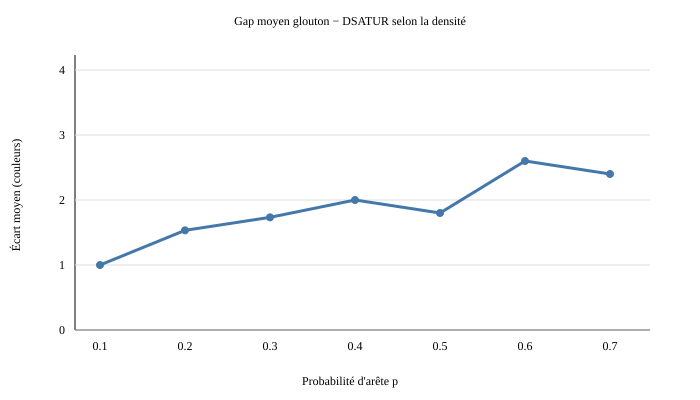

In [12]:
// Le balayage répète les graphes à chaque densité et calcule le gap sur ces échantillons.
// Des points voisins peuvent fluctuer : aucune monotonie générale n’est supposée.
var ps = new[]
{
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7
};
int nSweep = 15;
var gaps = new List<double>();
Console.WriteLine("Densité | gap moyen | victoires DSATUR | égalités");
foreach (double p in ps)
{
    var delta = Enumerable.Range(0, nSweep).Select(_ =>
    {
        var g = Generer(50, p, rng.Next(1, 1000000000));
        return Glouton(g).Item1 - Dsatur(g).Item1;
    }).ToArray();
    gaps.Add(delta.Average());
    Console.WriteLine($"{p:F2}    | {delta.Average():F3}     | {delta.Count(d => d > 0)}/{nSweep}             | {delta.Count(d => d == 0)}");
}

var sv2 = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='400' viewBox='0 0 700 400'><rect width='700' height='400' fill='white'/><text x='350' y='25' text-anchor='middle'>Gap moyen glouton − DSATUR selon la densité</text><line x1='75' y1='330' x2='650' y2='330' stroke='black'/><line x1='75' y1='55' x2='75' y2='330' stroke='black'/><text x='350' y='385' text-anchor='middle'>Probabilité d'arête p</text><text x='20' y='195' transform='rotate(-90 20 195)' text-anchor='middle'>Écart moyen (couleurs)</text>");
double ymax = Math.Ceiling(gaps.Max() + .5);
for (int t = 0; t <= ymax; t++)
{
    double y = 330 - 260 * t / ymax;
    sv2.Append($"<line x1='75' y1='{y:F2}' x2='650' y2='{y:F2}' stroke='#ddd'/><text x='65' y='{y + 4:F2}' text-anchor='end'>{t}</text>");
}

var pts = Enumerable.Range(0, ps.Length).Select(i => (x: 100 + i * 85, y: 330 - 260 * gaps[i] / ymax)).ToArray();
sv2.Append("<polyline fill='none' stroke='#4477aa' stroke-width='3' points='");
sv2.Append(string.Join(" ", pts.Select(v => $"{v.x},{v.y:F2}")));
sv2.Append("'/>");
for (int i = 0; i < ps.Length; i++)
    sv2.Append($"<circle cx='{pts[i].x}' cy='{pts[i].y:F2}' r='4' fill='#4477aa'/><text x='{pts[i].x}' y='350' text-anchor='middle'>{ps[i]:F1}</text>");
sv2.Append("</svg>");
display(new Svg(sv2.ToString()));


### Lecture du résultat

Le tableau montre le gap moyen et le nombre de victoires. La courbe est une estimation issue de 15 graphes par densité ; elle ne prouve pas une croissance monotone.

### Exercice 3 — Ajouter CP-SAT au balayage

Calculez le gap moyen DSATUR − CP-SAT sur les graphes fournis, en excluant les résolutions sans solution et en retournant `null` si aucune n'a abouti. Le solveur est fourni en callback : appelez-le une fois pour chaque graphe au budget transmis. Une fois la garde satisfaite, le carnet balaie les sept densités avec cinq graphes chacune. Le gap moyen mesuré est 1,000 pour p=0,1 et 1,800 pour p=0,5 ; il fluctue ensuite.

In [13]:
double? GapCp(Graphe[] graphes, double limite, Func<Graphe, double, (int? , string)> solveur)
{
    return null;
} // TODO : appeler solveur pour chaque graphe et moyenner les écarts où une solution existe

(bool complet, double? valeur) VerifierGap(Graphe[] graphes, double limite)
{
    var appels = new Dictionary<Graphe, (int? , string)>();
    (int? , string) Observe(Graphe g, double budget)
    {
        if (!graphes.Contains(g) || appels.ContainsKey(g) || budget != limite)
            throw new Exception("Appel solveur inattendu ou répété");
        var sortie = CpColor(g, budget);
        appels[g] = sortie;
        return sortie;
    }

    double? rep = GapCp(graphes, limite, Observe);
    if (rep.HasValue && !double.IsFinite(rep.Value))
        throw new Exception("Gap non fini");
    if (appels.Count != graphes.Length)
    {
        if (rep.HasValue)
            throw new Exception("Gap sans résoudre tous les graphes");
        return (false, null);
    }

    var differences = graphes.Where(g => appels[g].Item1.HasValue).Select(g => (double)(Dsatur(g).Item1 - appels[g].Item1.Value)).ToArray();
    double? attendu = differences.Length == 0 ? null : differences.Average();
    if (rep.HasValue != attendu.HasValue || (rep.HasValue && Math.Abs(rep.Value - attendu.Value) > 1e-9))
        throw new Exception("Gap CP-SAT incorrect");
    return (true, rep);
}

var triangle = new Graphe(3);
triangle.Arete(0, 1);
triangle.Arete(1, 2);
triangle.Arete(0, 2);
var chemin = new Graphe(3);
chemin.Arete(0, 1);
chemin.Arete(1, 2);
var difficile = Generer(15, 0.4, 35);
var fixture1 = VerifierGap(new[] { triangle, chemin }, 2.0);
var fixture2 = VerifierGap(new[] { difficile }, 2.0);
var fixture3 = VerifierGap(new[] { difficile }, 0.0);
if (!(fixture1.complet && fixture2.complet && fixture3.complet))
    Console.WriteLine("Exercice 3 à compléter : gap CP-SAT");
else
{
    bool complet = true;
    foreach (double p in ps)
    {
        var groupe = Enumerable.Range(0, 5).Select(_ => Generer(50, p, rng.Next(1, 1000000000))).ToArray();
        var mesure = VerifierGap(groupe, 2.0);
        if (!mesure.complet)
        {
            Console.WriteLine($"p={p:F1} : réponse incomplète");
            complet = false;
            break;
        }

        Console.WriteLine($"p={p:F1} : gap DSATUR − CP-SAT = {(mesure.valeur.HasValue ? mesure.valeur.Value.ToString("F3") : "aucune solution")}, 5 résolutions");
    }

    if (complet)
        Console.WriteLine("Exercice 3 : sept densités et 35 résolutions contrôlées");
}


Exercice 3 à compléter : gap CP-SAT


## 8. Synthèse et exercices

Les trois exercices sont répartis après les notions : Welsh–Powell, bootstrap de la médiane et balayage avec CP-SAT. Comparez moyenne et médiane sans déduire à elles seules la forme d'une distribution.

## À retenir

- Une comparaison sur un seul graphe peut être atypique ; apparier les stratégies par graphe conserve l'information commune.
- Le bootstrap encadre une moyenne, Wilcoxon teste les différences appariées et Bonferroni ajuste les comparaisons multiples.
- Une solution CP-SAT faisable donne une borne supérieure ; seul `Optimal` prouve l'optimum du modèle. Les échecs ne sont pas des mesures du solveur.

## Vérifiez votre compréhension

1. Pourquoi apparier les observations ?

<details><summary>Réponse</summary>
Chaque différence compare les stratégies sur le même graphe et tient compte de la difficulté propre à cette instance.
</details>

2. Que signifie `Feasible` pour CP-SAT ?

<details><summary>Réponse</summary>
Une coloration valide a été trouvée, sans preuve d'optimalité.
</details>

3. Que change la correction de Bonferroni ?

<details><summary>Réponse</summary>
Elle divise le seuil par le nombre de comparaisons afin de contrôler le risque global de faux positif.
</details>

## Pour aller plus loin

[App-2 — Coloration de graphes](App-02-GraphColoring-Python.ipynb) et [Sudoku-18b — comparaison statistique](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb). Consulter aussi les documentations [SciPy Wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html), [NetworkX](https://networkx.org/) et [OR-Tools](https://developers.google.com/optimization).